# Reverse-Engineering a Portfolio Dataset: Returns, Covariances and the Efficient Frontier

This notebook reconstructs, step by step, how the dataset behind the
[Gurobi Finance](https://gurobi-finance.readthedocs.io/) *Mean-Variance* examples was built, and then
uses it to trace the **efficient frontier**. It belongs to the first phase of my
[Portfolio Optimization project](../Projects/Portfolio-Optimization/).

Gurobi Finance ships four pre-processed `.pkl` files but does not document where the prices come
from. Every model downstream depends on two estimated inputs, the vector of **expected returns**
$\mu$ and the **covariance matrix** $\Sigma$, so before any modelling it is worth knowing exactly how
they were produced and which biases they carry.

**Contents**

1. Setup and data
2. The four files
3. From prices to returns: reproducing $\Sigma$ exactly
4. Reproducing $\mu$: Jorion's Bayes–Stein shrinkage
5. Where do the prices come from? Forensic evidence
6. An X-ray of the data
7. The efficient frontier: closed form vs. long-only
8. Takeaways for building our own dataset

> **Requirements:** NumPy, pandas, SciPy and Matplotlib. Section 7 also uses `gurobipy`, which
> needs a Gurobi license (free for academic use). The data are downloaded automatically from the
> Gurobi Finance documentation the first time the notebook runs; they are not redistributed here.

## 1. Setup and data

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import zipfile

import numpy as np
import pandas as pd
import scipy.linalg as la
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
DATA_URL = "https://gurobi-finance.readthedocs.io/en/latest/gurobi_finance_data.zip"
FILES = ["subset_weekly_closings_10yrs.pkl", "mu.pkl", "sigma.pkl", "stock_data.pkl"]

if not all((DATA_DIR / f).exists() for f in FILES):
    DATA_DIR.mkdir(exist_ok=True)
    zip_path, _ = urlretrieve(DATA_URL, DATA_DIR / "gurobi_finance_data.zip")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

# Plot style: three categorical slots, neutral ink for text and reference lines
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#b5b3ad", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 4.5), "font.size": 10,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "lines.linewidth": 2, "legend.frameon": False,
})

## 2. The four files

| File | Content |
|---|---|
| `subset_weekly_closings_10yrs.pkl` | Weekly closing prices: one row per week, one column per ticker |
| `mu.pkl` | Weekly expected returns (%), one per stock |
| `sigma.pkl` | Covariance matrix of weekly returns (%) |
| `stock_data.pkl` | Per ticker: market capitalisation, sector, company name and a 1–10 "risk" score |

In [2]:
prices = pd.read_pickle(DATA_DIR / "subset_weekly_closings_10yrs.pkl")
mu_gurobi = pd.read_pickle(DATA_DIR / "mu.pkl")
sigma_gurobi = pd.read_pickle(DATA_DIR / "sigma.pkl")
stock_data = pd.read_pickle(DATA_DIR / "stock_data.pkl")

objs = (prices, mu_gurobi, sigma_gurobi, stock_data)
pd.DataFrame({"type": [type(o).__name__ for o in objs], "shape": [o.shape for o in objs]}, index=FILES)

,type,shape
subset_weekly_closings_10yrs.pkl,DataFrame,"(568, 462)"
mu.pkl,Series,"(462,)"
sigma.pkl,DataFrame,"(462, 462)"
stock_data.pkl,DataFrame,"(462, 4)"


In [3]:
print("First week:     ", prices.index.min().date())
print("Last week:      ", prices.index.max().date())
print("Weekdays in index:", sorted({d.day_name() for d in prices.index}))
print("Missing values: ", int(prices.isna().sum().sum()))

First week:      2013-01-07
Last week:       2023-11-20
Weekdays in index: ['Monday']
Missing values:  0


Despite the `10yrs` in its name, the price file covers **568 weeks** (almost ten years and eleven
months), every date is a **Monday**, and there is **not a single missing value**. The first three
files share the same ticker order; `stock_data.pkl` uses a different one (sorted by market cap), so
any join between them must be done by label, never by position.

## 3. From prices to returns: reproducing $\Sigma$ exactly

For each stock $i$ and week $t$ the **simple rate of return** (in %) is

$$R_{t,i} = 100\,\frac{P_{t,i} - P_{t-1,i}}{P_{t-1,i}}, \qquad t = 1,\dots,T.$$

From the $T \times n$ matrix of returns, the classical estimators are the **sample mean** and the
unbiased **sample covariance matrix**:

$$\hat\mu_i = \frac1T \sum_{t=1}^T R_{t,i}, \qquad
\hat\Sigma_{ij} = \frac{1}{T-1}\sum_{t=1}^T \big(R_{t,i}-\hat\mu_i\big)\big(R_{t,j}-\hat\mu_j\big).$$

In [4]:
r = prices.pct_change().iloc[1:] * 100        # weekly returns in %
T, n = r.shape
mu_hat, Sigma_hat = r.mean(), r.cov()

print(f"T = {T} weekly returns, n = {n} stocks, T/n = {T / n:.2f}")
print(f"max |Sigma_hat - sigma.pkl| = {(Sigma_hat - sigma_gurobi).abs().max().max():.2e}")
print(f"max |mu_hat    - mu.pkl|    = {(mu_hat - mu_gurobi).abs().max():.2f}")

T = 567 weekly returns, n = 462 stocks, T/n = 1.23
max |Sigma_hat - sigma.pkl| = 0.00e+00
max |mu_hat    - mu.pkl|    = 0.54


The covariance matrix is reproduced **exactly** (difference 0). The expected returns are not:
`mu.pkl` differs from the sample mean by up to half a percentage point per week, which is larger
than the typical weekly return itself. Something else was applied to $\hat\mu$.

## 4. Reproducing $\mu$: Jorion's Bayes–Stein shrinkage

The sample mean is a very noisy estimator. With $T = 567$ weeks and a typical weekly volatility of
$\sigma_i \approx 3.5\%$, the standard error of each $\hat\mu_i$ is
$\sigma_i/\sqrt{T} \approx 0.15\%$, the same order of magnitude as the means themselves
($\approx 0.3\%$). Optimisers are extremely sensitive to errors in $\mu$, so Gurobi Finance applies
the **Bayes–Stein shrinkage estimator** of Jorion (1986), which pulls every sample mean towards a
common target, the return $\mu_0$ of the **Global Minimum Variance (GMV) portfolio**:

$$\hat\mu^{\,\mathrm{BS}} = (1-w)\,\hat\mu + w\,\mu_0\mathbf 1, \qquad
\mu_0 = \frac{\mathbf 1^\top\Sigma^{-1}\hat\mu}{\mathbf 1^\top\Sigma^{-1}\mathbf 1},$$

$$w = \frac{n+2}{(n+2) + T\,(\hat\mu-\mu_0\mathbf 1)^\top\,\Sigma^{-1}\,(\hat\mu-\mu_0\mathbf 1)}, \qquad
\Sigma = \frac{T-1}{T-n-2}\,\hat\Sigma.$$

The factor $\frac{T-1}{T-n-2}$ comes from the inverse Wishart distribution: it makes $\Sigma^{-1}$ an
unbiased estimator of the true inverse covariance. The **shrinkage intensity** $w \in (0,1)$ is
large when the sample means are close to each other relative to their noise, and small when they
are clearly different.

In [5]:
Sigma_bc = (T - 1) / (T - n - 2) * Sigma_hat          # bias-corrected covariance
z = la.solve(Sigma_bc, np.ones(n), assume_a="pos")    # Sigma^{-1} 1
mu_0 = mu_hat @ z / z.sum()                           # GMV return (shrinkage target)
d = mu_hat - mu_0
w = (n + 2) / (n + 2 + T * (d @ la.solve(Sigma_bc, d, assume_a="pos")))
mu_bs = (1 - w) * mu_hat + w * mu_0

print(f"correction factor (T-1)/(T-n-2) = {(T - 1) / (T - n - 2):.2f}")
print(f"target mu_0 = {mu_0:.3f} % per week, shrinkage intensity w = {w:.3f}")
print(f"max |mu_BS - mu.pkl| = {(mu_bs - mu_gurobi).abs().max():.1e}")

correction factor (T-1)/(T-n-2) = 5.50
target mu_0 = 0.180 % per week, shrinkage intensity w = 0.566
max |mu_BS - mu.pkl| = 2.6e-14


Match up to floating-point rounding. Each entry of `mu.pkl` is therefore **57 % the GMV return and
43 % the stock's own historical mean**. The correction factor is large ($\approx 5.5$) because $T$
barely exceeds $n$; with so few observations per stock, the estimator trusts the individual means
very little.

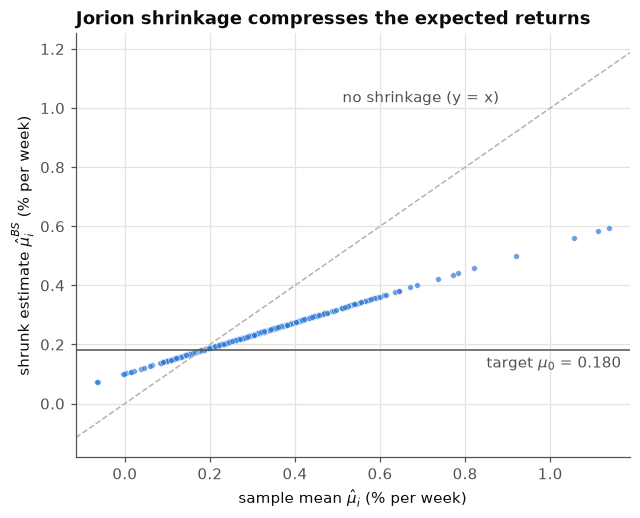

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5))
lims = [mu_hat.min() - 0.05, mu_hat.max() + 0.05]
ax.plot(lims, lims, color=MUTED, lw=1, ls="--")
ax.axhline(mu_0, color=INK_2, lw=1)
ax.scatter(mu_hat, mu_bs, s=14, color=BLUE, alpha=0.7, edgecolor="white", linewidth=0.4)
ax.text(0.88, 1.02, "no shrinkage (y = x)", color=INK_2, ha="right")
ax.text(lims[1] - 0.02, mu_0 - 0.06, rf"target $\mu_0$ = {mu_0:.3f}", color=INK_2, ha="right")
ax.set(xlim=lims, xlabel=r"sample mean $\hat\mu_i$ (% per week)",
       ylabel=r"shrunk estimate $\hat\mu_i^{BS}$ (% per week)")
ax.set_title("Jorion shrinkage compresses the expected returns")
plt.show()

## 5. Where do the prices come from? Forensic evidence

Gurobi Finance does not name its source, but the files leave enough clues.

**Adjusted prices.** A stock split multiplies the number of shares and divides the price. In an
unadjusted series a 4-for-1 split shows up as a $-75\%$ "return". The weeks of the big splits of
2020–2022 show nothing unusual, so the closes are **adjusted** for splits (and dividends).

In [7]:
splits = [("AAPL", "2020-08-31", 4), ("TSLA", "2020-08-31", 5), ("NVDA", "2021-07-19", 4),
          ("AMZN", "2022-06-06", 20), ("GOOGL", "2022-07-18", 20), ("TSLA", "2022-08-22", 3)]
pd.DataFrame(
    [(tk, wk, f"{k}-for-1", round(r.loc[wk, tk], 1), round(-100 * (1 - 1 / k), 1))
     for tk, wk, k in splits],
    columns=["ticker", "week", "split", "observed return (%)", "if unadjusted (%)"],
)

,ticker,week,split,observed return (%),if unadjusted (%)
0,AAPL,2020-08-31,4-for-1,8.0,-75.0
1,TSLA,2020-08-31,5-for-1,7.7,-80.0
2,NVDA,2021-07-19,4-for-1,-8.8,-75.0
3,AMZN,2022-06-06,20-for-1,15.5,-95.0
4,GOOGL,2022-07-18,20-for-1,-3.7,-95.0
5,TSLA,2022-08-22,3-for-1,2.3,-66.7


**When the stock list was taken.** The universe matches the S&P 500 constituents between two index
rebalances: Blackstone (BX) replaced Lincoln National (LNC) and Newell Brands (NWL) on
18 September 2023, and Sealed Air (SEE) and Alaska Air (ALK) were replaced by Jabil (JBL) and
Builders FirstSource (BLDR) on 18 December 2023.

In [8]:
cols = set(prices.columns)
{tk: tk in cols for tk in ["BX", "LNC", "NWL", "SEE", "ALK", "JBL", "BLDR"]}

{'BX': True,
 'LNC': False,
 'NWL': False,
 'SEE': True,
 'ALK': True,
 'JBL': False,
 'BLDR': False}

**The provider.** Three independent fingerprints point to Yahoo Finance (most likely through the
`yfinance` library): tickers with a dash (`BRK-B`, `BF-B`, Yahoo's notation), weekly bars dated on
Mondays (what `interval="1wk"` returns), and sector labels from Yahoo/Morningstar rather than GICS
(*Consumer Cyclical*, *Financial Services*, *Healthcare*… where GICS says *Consumer Discretionary*,
*Financials*, *Health Care*). The 1–10 `Risk` score is spread almost uniformly, like Yahoo's
governance-risk deciles.

In [9]:
print("Tickers with a dash:", [c for c in prices.columns if "-" in c])
print("\nSectors:\n", stock_data["Sector"].value_counts().to_string())
print("\nRisk score counts (1-10):", stock_data["Risk"].value_counts().sort_index().astype(int).tolist())

Tickers with a dash: ['BF-B', 'BRK-B']

Sectors:
 Sector
Industrials               67
Technology                65
Financial Services        64
Healthcare                60
Consumer Cyclical         53
Consumer Defensive        34
Utilities                 29
Real Estate               29
Energy                    23
Basic Materials           20
Communication Services    18

Risk score counts (1-10): [50, 46, 45, 48, 50, 47, 45, 46, 40, 45]


**The filter, and its price: survivorship bias.** Only companies with a *complete* price history
since January 2013 were kept (about 503 index lines → 462 stocks). The universe is therefore the
index **as of late 2023, followed backwards**: firms that left the index through bankruptcy,
acquisition or decline are missing, while firms that entered because they had already soared are
present with their full run-up (Tesla and Enphase joined the S&P 500 in 2020–2021 but count here
from 2013). As a result, $\hat\mu$ overstates what an investor could have earned in 2013.

## 6. An X-ray of the data

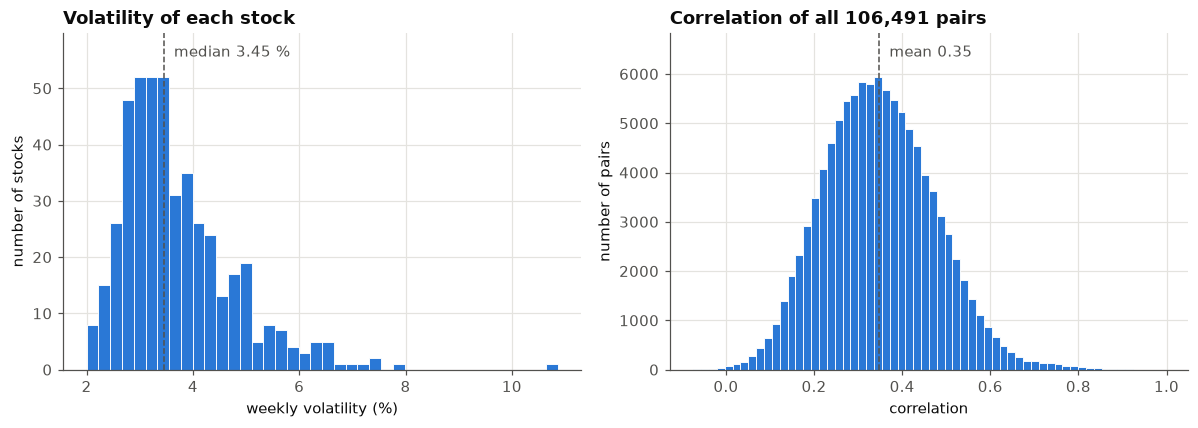

least / most volatile: PEP (2.00 %), ENPH (10.86 %)
negative correlations: 72 of 106,491 pairs


In [10]:
vol = pd.Series(np.sqrt(np.diag(Sigma_hat)), index=Sigma_hat.index)
corr = r.corr().to_numpy()
pairs = corr[np.triu_indices(n, k=1)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, bins, label in [(axes[0], vol, 40, f"median {vol.median():.2f} %"),
                               (axes[1], pairs, 60, f"mean {pairs.mean():.2f}")]:
    counts, _, _ = ax.hist(data, bins=bins, color=BLUE, edgecolor="white", linewidth=0.6)
    ref = np.median(data) if ax is axes[0] else data.mean()
    ax.set_ylim(0, counts.max() * 1.15)
    ax.axvline(ref, color=INK_2, lw=1, ls="--")
    ax.text(ref, counts.max() * 1.07, f"  {label}", color=INK_2)

axes[0].set(xlabel="weekly volatility (%)", ylabel="number of stocks")
axes[0].set_title("Volatility of each stock")

axes[1].set(xlabel="correlation", ylabel="number of pairs")
axes[1].set_title(f"Correlation of all {len(pairs):,} pairs")
plt.tight_layout()
plt.show()

print(f"least / most volatile: {vol.idxmin()} ({vol.min():.2f} %), {vol.idxmax()} ({vol.max():.2f} %)")
print(f"negative correlations: {(pairs < 0).sum()} of {len(pairs):,} pairs")

Almost every pair of stocks moves together (only 72 of 106,491 correlations are negative). That
common movement is the **market factor**, and it is visible in the spectrum of $\hat\Sigma$: the
largest eigenvalue alone explains over a third of the total variance.

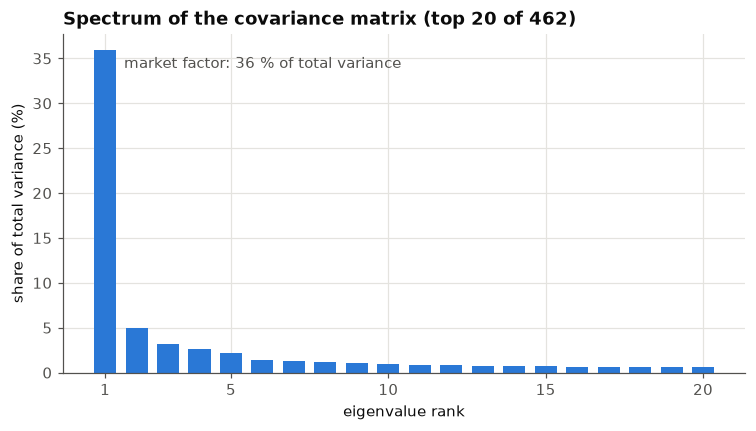

largest / smallest eigenvalue: 2503.3 / 0.0072  ->  condition number 3.5e+05


In [11]:
eig = np.linalg.eigvalsh(Sigma_hat.to_numpy())[::-1]      # descending
share = eig / eig.sum()

fig, ax = plt.subplots(figsize=(8, 4))
k = 20
ax.bar(np.arange(1, k + 1), 100 * share[:k], color=BLUE, width=0.7)
ax.text(1.6, 100 * share[0] - 2, f"market factor: {100 * share[0]:.0f} % of total variance", color=INK_2)
ax.set(xlabel="eigenvalue rank", ylabel="share of total variance (%)", xticks=[1, 5, 10, 15, 20])
ax.set_title(f"Spectrum of the covariance matrix (top {k} of {n})")
plt.show()

print(f"largest / smallest eigenvalue: {eig[0]:.1f} / {eig[-1]:.4f}  ->  condition number {eig[0] / eig[-1]:.1e}")

A condition number of about $3.5 \times 10^5$ means that $\hat\Sigma$ is **nearly singular**: with
$T/n \approx 1.23$ there is barely enough data to estimate its $n(n+1)/2 = 106{,}953$ entries.
Directions with tiny eigenvalues look almost riskless in-sample, and an optimiser will exploit
them. Section 7 shows the consequence.

## 7. The efficient frontier: closed form vs. long-only

The Markowitz problem finds, for each target return $m$, the portfolio of minimum variance:

$$\min_{x \in \mathbb R^n} \; x^\top \Sigma x \quad \text{s.t.} \quad \mu^\top x = m, \quad \mathbf 1^\top x = 1.$$

**With short-selling allowed** (no sign constraint on $x$) it has a closed-form solution. The
Lagrangian gives $x^* = \Sigma^{-1}(\lambda \mathbf 1 + \gamma \mu)$, and imposing both constraints
yields

$$\sigma^2(m) = \frac{a\,m^2 - 2\,b\,m + c}{ac - b^2}, \qquad
a = \mathbf 1^\top\Sigma^{-1}\mathbf 1, \quad b = \mathbf 1^\top\Sigma^{-1}\mu, \quad c = \mu^\top\Sigma^{-1}\mu,$$

a hyperbola in the $(\sigma, m)$ plane whose vertex is the GMV portfolio,
$\big(1/\sqrt a,\; b/a\big)$.

**Long-only** ($x \ge 0$) breaks the closed form: the problem becomes a convex quadratic program,
solved here with Gurobi for a grid of target returns. As in Gurobi Finance, $\mu$ is the shrunk
estimate and $\Sigma$ the sample covariance.

In [12]:
mu, S = mu_gurobi.to_numpy(), sigma_gurobi.to_numpy()
S_inv_1, S_inv_mu = la.solve(S, np.ones(n), assume_a="pos"), la.solve(S, mu, assume_a="pos")
a, b, c = S_inv_1.sum(), S_inv_1 @ mu, mu @ S_inv_mu
D = a * c - b**2

m_grid = np.linspace(b / a, mu.max(), 200)
sd_free = np.sqrt((a * m_grid**2 - 2 * b * m_grid + c) / D)
x_gmv_free = S_inv_1 / a

In [13]:
import gurobipy as gp
from gurobipy import GRB

env = gp.Env(params={"OutputFlag": 0})
model = gp.Model(env=env)
x = model.addMVar(n, lb=0.0)                  # long-only weights
model.addConstr(x.sum() == 1)
target = model.addConstr(mu @ x >= 0)         # RHS updated in the loop
model.setObjective(x @ S @ x, GRB.MINIMIZE)

model.optimize()                              # long-only GMV (target not binding)
x_gmv_long = x.X.copy()

m_long = np.linspace(mu @ x_gmv_long, mu.max(), 40)
sd_long = []
for m in m_long:
    target.RHS = m
    model.optimize()
    sd_long.append(np.sqrt(model.ObjVal))
sd_long = np.array(sd_long)

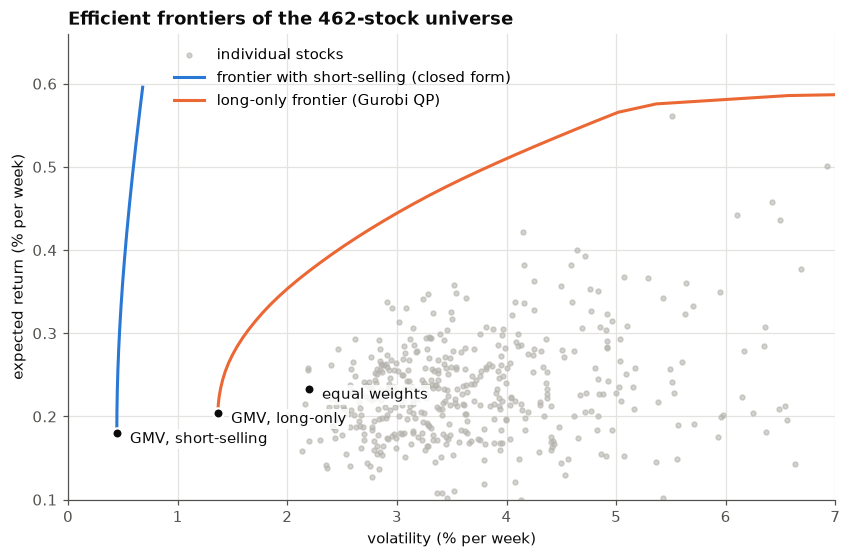

In [14]:
x_ew = np.full(n, 1 / n)
points = {
    "GMV, short-selling": x_gmv_free,
    "GMV, long-only": x_gmv_long,
    "equal weights": x_ew,
}

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(np.sqrt(np.diag(S)), mu, s=10, color=MUTED, alpha=0.6, label="individual stocks")
ax.plot(sd_free, m_grid, color=BLUE, label="frontier with short-selling (closed form)")
ax.plot(sd_long, m_long, color=ORANGE, label="long-only frontier (Gurobi QP)")
for name, xp in points.items():
    s_p, m_p = np.sqrt(xp @ S @ xp), mu @ xp
    ax.scatter(s_p, m_p, s=45, color=INK, zorder=3, edgecolor="white", linewidth=1.5)
    ax.text(s_p + 0.12, m_p - 0.012, name, color=INK, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.85))
ax.set(xlim=(0, 7), ylim=(0.1, 0.66),
       xlabel="volatility (% per week)", ylabel="expected return (% per week)")
ax.set_title("Efficient frontiers of the 462-stock universe")
ax.legend(loc="upper left", bbox_to_anchor=(0.12, 1.0))
plt.show()

In-sample, allowing short sales seems to cut risk dramatically: the unconstrained GMV portfolio has
a third of the volatility of the long-only one. The table below shows the price of that apparent
free lunch.

In [15]:
def describe(xp):
    return {
        "volatility (%/wk)": np.sqrt(xp @ S @ xp),
        "expected return (%/wk)": mu @ xp,
        "holdings": int((np.abs(xp) > 1e-4).sum()),
        "short positions": int((xp < -1e-4).sum()),
        "gross exposure sum|x_i|": np.abs(xp).sum(),
    }

pd.DataFrame({k: describe(v) for k, v in points.items()}).round(3)

,"GMV, short-selling","GMV, long-only",equal weights
volatility (%/wk),0.445,1.367,2.196
expected return (%/wk),0.180,0.204,0.233
holdings,462.000,38.000,462.000
short positions,216.000,0.000,0.000
gross exposure sum|x_i|,20.752,1.000,1.000


The unconstrained GMV portfolio holds all 462 stocks, shorts 216 of them and has a **gross exposure
of about 21 times the capital**. It is exploiting exactly those near-zero eigenvalues of $\hat\Sigma$
from Section 6: directions that look riskless only because there is not enough data to see their
risk. This is Michaud's (1989) *error maximisation* effect. The long-only portfolio, by contrast,
concentrates on 38 stocks with no leverage.

Two practical lessons follow. First, constraints such as $x \ge 0$ act as **regularisation** as
well as modelling real restrictions (Jagannathan & Ma, 2003). Second, the quality of $\Sigma$
matters as much as that of $\mu$: shrinkage of the covariance matrix or a **factor model** (whose
first factor we already saw in the spectrum) are the natural next steps.

## 8. Takeaways for building our own dataset

| Decision | What Gurobi Finance did | What to consider |
|---|---|---|
| Universe | Current S&P 500 constituents | A *point-in-time* constituent list, to avoid survivorship bias |
| Source | Yahoo Finance (inferred) | Free and convenient, but no delisted firms and no quality guarantee; CRSP (via WRDS) is the academic standard |
| Frequency | Weekly | Daily gives more observations but more noise; monthly, very few |
| Period | About 11 years | Longer periods raise $T$ but make parameters less stable |
| Prices | Adjusted closes | Adjusted, recording the download date (Yahoo rewrites past prices with every dividend) |
| Missing data | Drop the whole stock | Drop, impute or shorten the period, as an explicit decision |
| Estimation | Bayes–Stein $\mu$, sample $\Sigma$ | $T/n$ close to 1 makes $\hat\Sigma$ ill-conditioned: covariance shrinkage or factor models |

### References

- Gurobi Optimization. *Gurobi Finance: Mean-Variance Portfolio Optimization*. <https://gurobi-finance.readthedocs.io>
- Jagannathan, R. and Ma, T. (2003). Risk reduction in large portfolios: why imposing the wrong constraints helps. *The Journal of Finance*, 58(4), 1651–1684.
- Jorion, P. (1986). Bayes–Stein estimation for portfolio analysis. *Journal of Financial and Quantitative Analysis*, 21(3), 279–292.
- Mansini, R., Ogryczak, W. and Speranza, M. G. (2015). *Linear and Mixed Integer Programming for Portfolio Optimization*. Springer.
- Markowitz, H. (1952). Portfolio selection. *The Journal of Finance*, 7(1), 77–91.
- Michaud, R. O. (1989). The Markowitz optimization enigma: is 'optimized' optimal? *Financial Analysts Journal*, 45(1), 31–42.